# Tail-risk study: scale-equivariant early magnitude distributions

This notebook explains every approach compared in `tailrisk/` and shows the saved
out-of-fold results. Nothing here retrains a model. The protocol and arm definitions are in
`tailrisk/README.md`. The narrative conclusions (positive and negative) are in
`tailrisk/FINDINGS.md`, reproduced at the end.

**Question.** From the first 1, 3 or 5 s after the P arrival at one station, can we reduce
the error on rare large earthquakes (M≥4, M≥5) *without* increasing the error on the bulk
of ordinary records?

**Key protocol choices**
1. *Leave-sequence-out CV.* All 1,159,249 INSTANCE records are split by Gardner–Knopoff
   aftershock sequences into 5 folds. The tail then has 346 M≥4 and 31 M≥5 events, instead of
   the 13 / 1 of the 2018 VAL split.
2. *Same trunk for every arm.* Only the predictive head / loss changes.
3. *Frontier evaluation.* For a posterior p, the rule "multiply the tail mass by r and take
   the median" is the Bayes action for the loss r·|e| on M≥4 and |e| otherwise. Sweeping r
   traces the best bulk/tail trade-off that p allows. We compare arms at *matched bulk MAE*.

In [1]:
import json, pandas as pd
from IPython.display import Image, display
EVAL = 'results/eval_cat_ce_mix_nll_mixgr_nll_eqgr_nll_eq_nll.json'
rep = json.load(open(EVAL))
print('records:', rep['n_records'], ' M>=4 events:', rep['n_M4_events'])

records: 1159249  M>=4 events: 346


## 1. Point metrics of the fixed actions

`mean` is the posterior-mean action; `med` is the posterior median (r = 1). M≥4 MAE is
record-weighted; M≥4 eventMAE gives every M≥4 earthquake equal weight. CVaR95 is the mean of
the worst 5% of absolute errors over *all* records (the "largest errors" sense of long tail).

In [2]:
rows = []
for arm, by_d in rep['arms'].items():
    for d, r in by_d.items():
        for act in ('mean_action', 'median_action'):
            m = r[act]
            rows.append({'arm': arm, 'deadline': d, 'action': act.split('_')[0], **{k: round(m[k], 4) for k in
                         ('MAE', 'MedAE', 'CVaR95', 'M>=4_MAE', 'M>=4_eventMAE', 'M>=5_MAE', 'M>=4_bias', 'FP4_rate')}})
pd.set_option('display.width', 200)
pd.DataFrame(rows).set_index(['deadline', 'action', 'arm']).sort_index()

MAE   MedAE  CVaR95  M>=4_MAE  M>=4_eventMAE  M>=5_MAE  M>=4_bias  FP4_rate
deadline action arm                                                                                      
1s       mean   cat_ce     0.3291  0.2497  1.1860    0.7684         0.7749    1.1007    -0.7193    0.0007
                eq_nll     0.3339  0.2576  1.1898    0.7624         0.7831    1.0581    -0.6969    0.0006
                eqgr_nll   0.3299  0.2504  1.1869    0.7298         0.7466    1.0037    -0.6535    0.0008
                mix_nll    0.3300  0.2508  1.1865    0.7555         0.7659    1.0645    -0.7018    0.0006
                mixgr_nll  0.3288  0.2495  1.1821    0.7405         0.7515    1.0430    -0.6837    0.0006
         median cat_ce     0.3272  0.2398  1.2148    0.7814         0.7879    1.1100    -0.7327    0.0008
                eq_nll     0.3331  0.2522  1.2125    0.7795         0.8023    1.0724    -0.7158    0.0006
                eqgr_nll   0.3277  0.2402  1.2136    0.7421         0.7608    1.0122    -0.6672    0.0008
                mix_nll    0.3277  0.2405  1.2134    0.7637         0.7753    1.0510    -0.7077    0.0006
                mixgr_nll  0.3267  0.2396  1.2086    0.7493         0.7621    1.0227    -0.6882    0.0007
3s       mean   cat_ce     0.2728  0.2023  1.0306    0.5927         0.6054    0.8352    -0.5389    0.0005
                eq_nll     0.2763  0.2078  1.0324    0.5749         0.6007    0.6591    -0.4893    0.0005
                eqgr_nll   0.2707  0.2000  1.0292    0.5492         0.5716    0.6309    -0.4546    0.0006
                mix_nll    0.2723  0.2019  1.0295    0.5717         0.5880    0.7824    -0.5122    0.0005
                mixgr_nll  0.2695  0.1990  1.0232    0.5582         0.5757    0.7399    -0.4951    0.0005
         median cat_ce     0.2714  0.1957  1.0577    0.6101         0.6231    0.8604    -0.5574    0.0006
                eq_nll     0.2757  0.2038  1.0564    0.5878         0.6152    0.6668    -0.5059    0.0005
                eqgr_nll   0.2691  0.1929  1.0587    0.5600         0.5836    0.6383    -0.4691    0.0006
                mix_nll    0.2704  0.1948  1.0566    0.5768         0.5941    0.7648    -0.5161    0.0005
                mixgr_nll  0.2679  0.1921  1.0514    0.5646         0.5834    0.7165    -0.4983    0.0005
5s       mean   cat_ce     0.2409  0.1741  0.9655    0.5472         0.5594    0.7842    -0.4896    0.0004
                eq_nll     0.2428  0.1780  0.9638    0.5132         0.5414    0.5514    -0.4222    0.0004
                eqgr_nll   0.2367  0.1699  0.9610    0.4939         0.5176    0.5384    -0.3962    0.0005
                mix_nll    0.2399  0.1731  0.9649    0.5255         0.5426    0.7208    -0.4656    0.0004
                mixgr_nll  0.2367  0.1703  0.9546    0.5101         0.5281    0.6747    -0.4440    0.0004
         median cat_ce     0.2400  0.1699  0.9895    0.5660         0.5784    0.8180    -0.5105    0.0005
                eq_nll     0.2422  0.1756  0.9860    0.5251         0.5553    0.5565    -0.4388    0.0004
                eqgr_nll   0.2352  0.1649  0.9887    0.5040         0.5290    0.5482    -0.4117    0.0005
                mix_nll    0.2383  0.1683  0.9901    0.5300         0.5480    0.7029    -0.4698    0.0005
                mixgr_nll  0.2351  0.1653  0.9820    0.5168         0.5366    0.6549    -0.4488    0.0004

## 2. Bulk-constrained comparisons against the reference arm

For each bootstrap replicate (whole sequences resampled), each arm picks the tail weight r
that minimizes its tail error subject to bulk MAE ≤ the reference arm's median-action bulk MAE
(`bulkcap0_*`), or ≤ that value × 1.002 (`bulkcap0.002_*`). The table shows arm minus
reference; negative means the arm achieves a lower tail error without spending more bulk
error. Brackets are 95% intervals. `tailcap_MAE` is the reverse comparison: the least bulk
MAE subject to M≥4 MAE ≤ the reference's. `median`/`mean` rows compare the fixed actions.

In [3]:
rows = []
for arm, by_d in rep.get('vs_ref', {}).items():
    for d, c in by_d.items():
        for key in ('bulkcap0_M>=4_MAE', 'bulkcap0_M>=4_eventMAE', 'bulkcap0_M>=5_MAE', 'bulkcap0.002_M>=4_MAE', 'tailcap_MAE'):
            v = c.get(key)
            if v:
                rows.append({'arm': arm, 'deadline': d, 'comparison': key, 'delta': round(v['mean'], 4),
                             'lo95': round(v['lo'], 4), 'hi95': round(v['hi'], 4), 'P(arm better)': round(v['p_arm_better'], 3)})
        for act in ('median', 'mean'):
            for key, v in c[act].items():
                if v:
                    rows.append({'arm': arm, 'deadline': d, 'comparison': f'{act} action {key}', 'delta': round(v['mean'], 4),
                                 'lo95': round(v['lo'], 4), 'hi95': round(v['hi'], 4), 'P(arm better)': round(v['p_arm_better'], 3)})
pd.DataFrame(rows).set_index(['comparison', 'deadline', 'arm']).sort_index()

delta    lo95    hi95  P(arm better)
comparison            deadline arm                                             
bulkcap0.002_M>=4_MAE 1s       cat_ce     0.0007 -0.0395  0.0700          0.597
                               eqgr_nll  -0.0077 -0.0511  0.0409          0.625
                               mixgr_nll -0.0448 -0.0640 -0.0290          1.000
                      3s       cat_ce     0.0797  0.0626  0.0912          0.000
                               eqgr_nll  -0.0457 -0.0713 -0.0252          1.000
...                                          ...     ...     ...            ...
tailcap_MAE           3s       mixgr_nll -0.0025 -0.0031 -0.0022          1.000
                      5s       cat_ce     0.0020  0.0015  0.0029          0.000
                               eq_nll     0.0033  0.0008  0.0054          0.001
                               eqgr_nll  -0.0033 -0.0039 -0.0029          1.000
                               mixgr_nll -0.0032 -0.0035 -0.0027          1.000

[141 rows x 4 columns]

## 3. Frontiers

Each curve is one arm's posterior evaluated over r. Lower-left is better. ● marks the median action, □ the mean action.

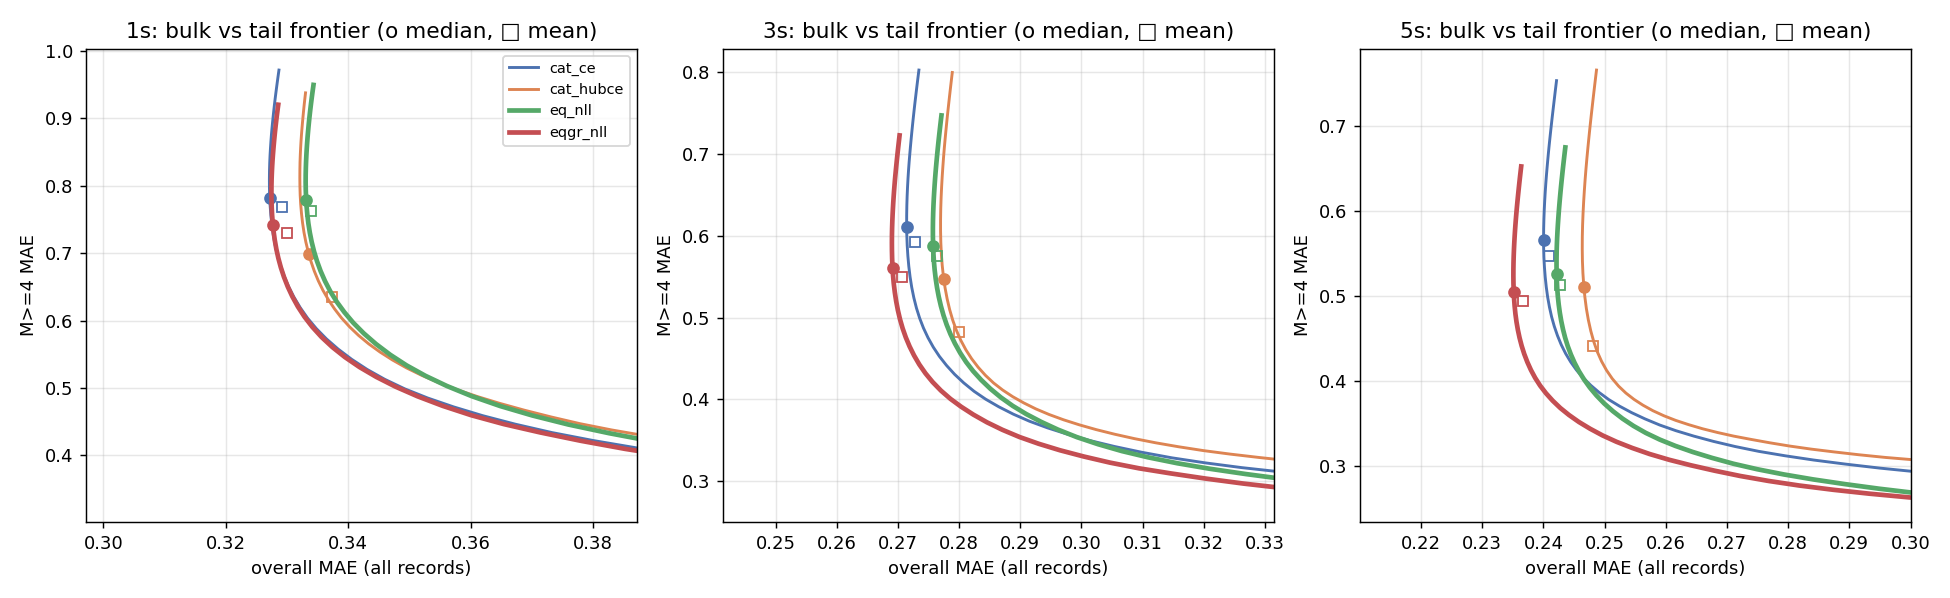

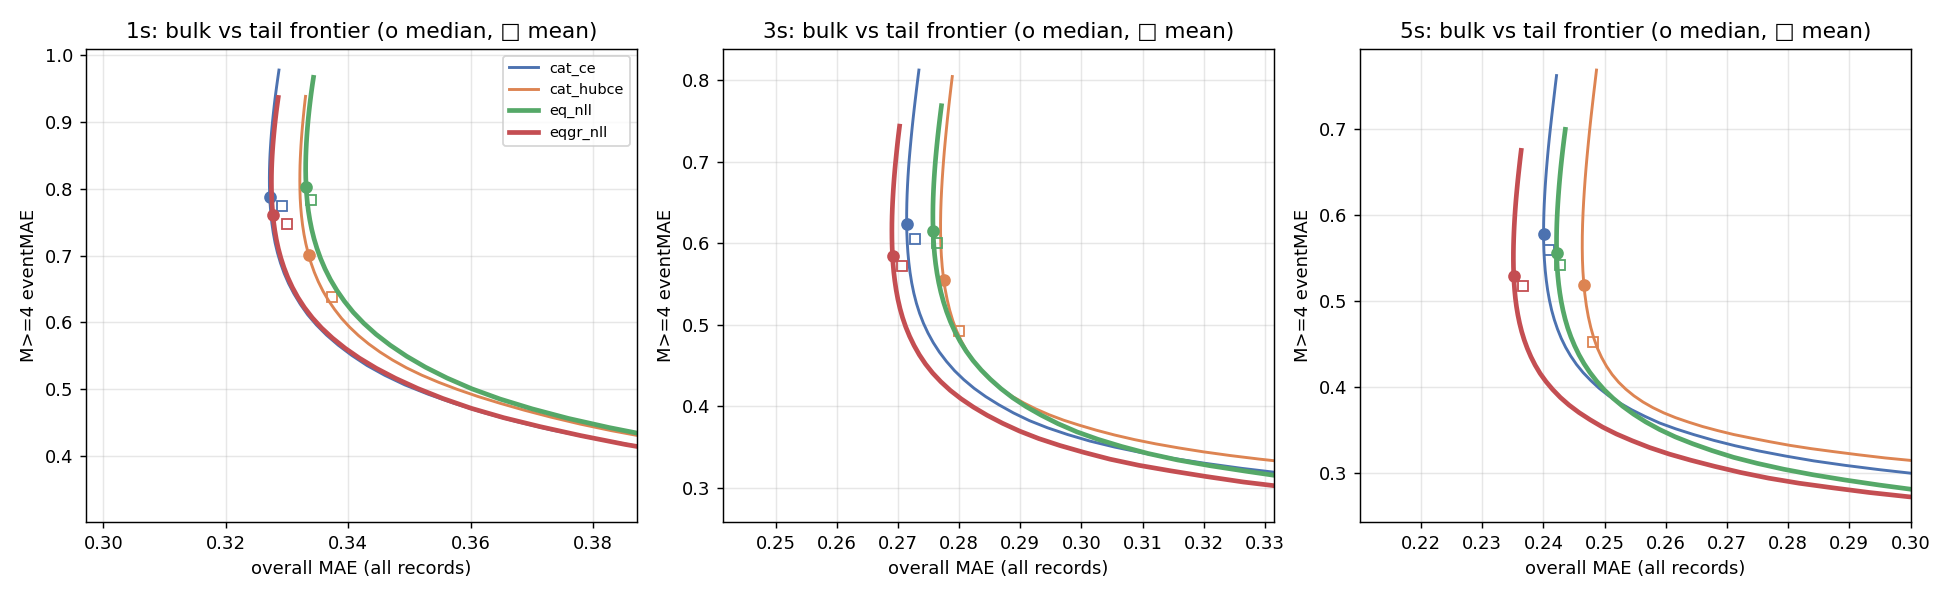

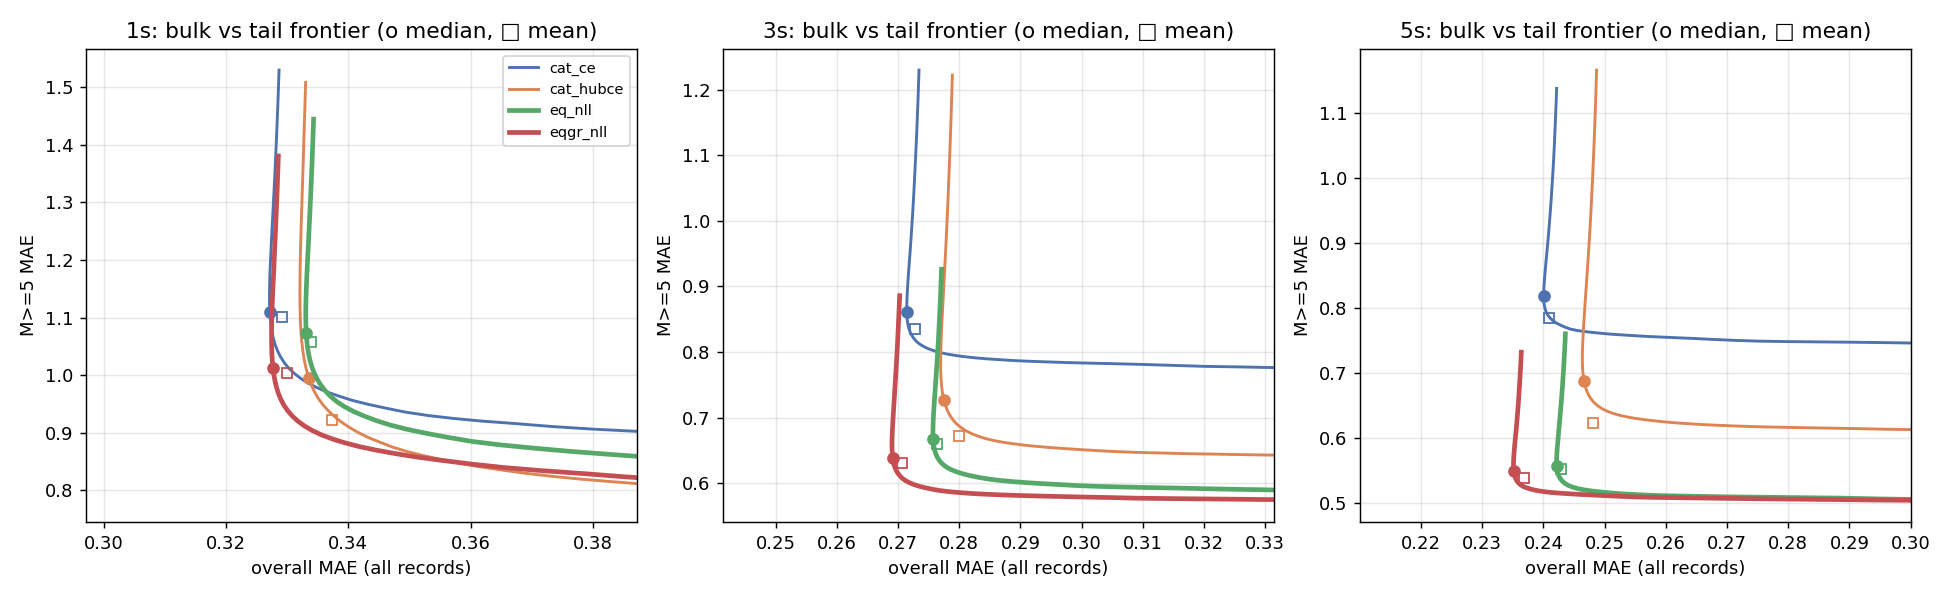

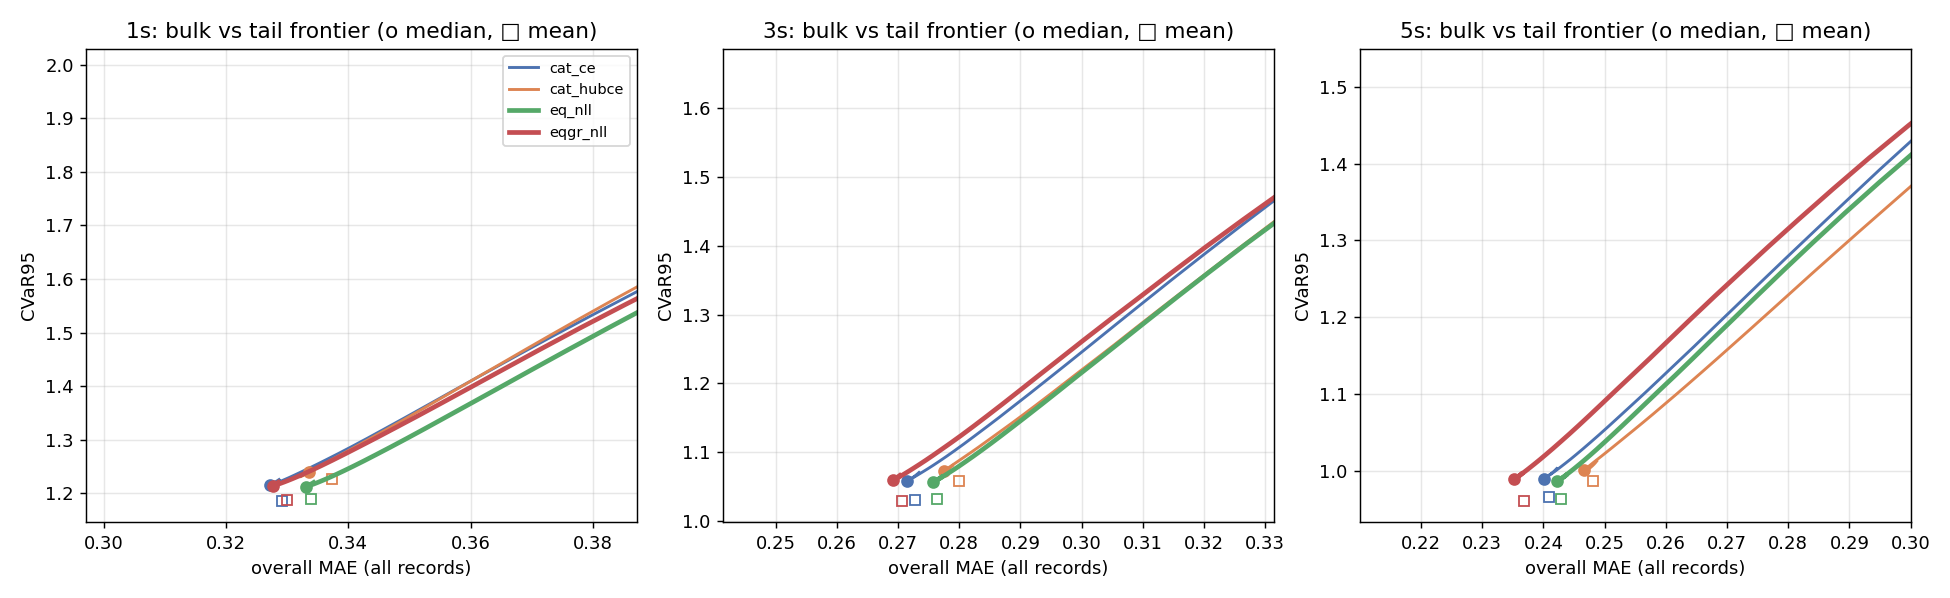

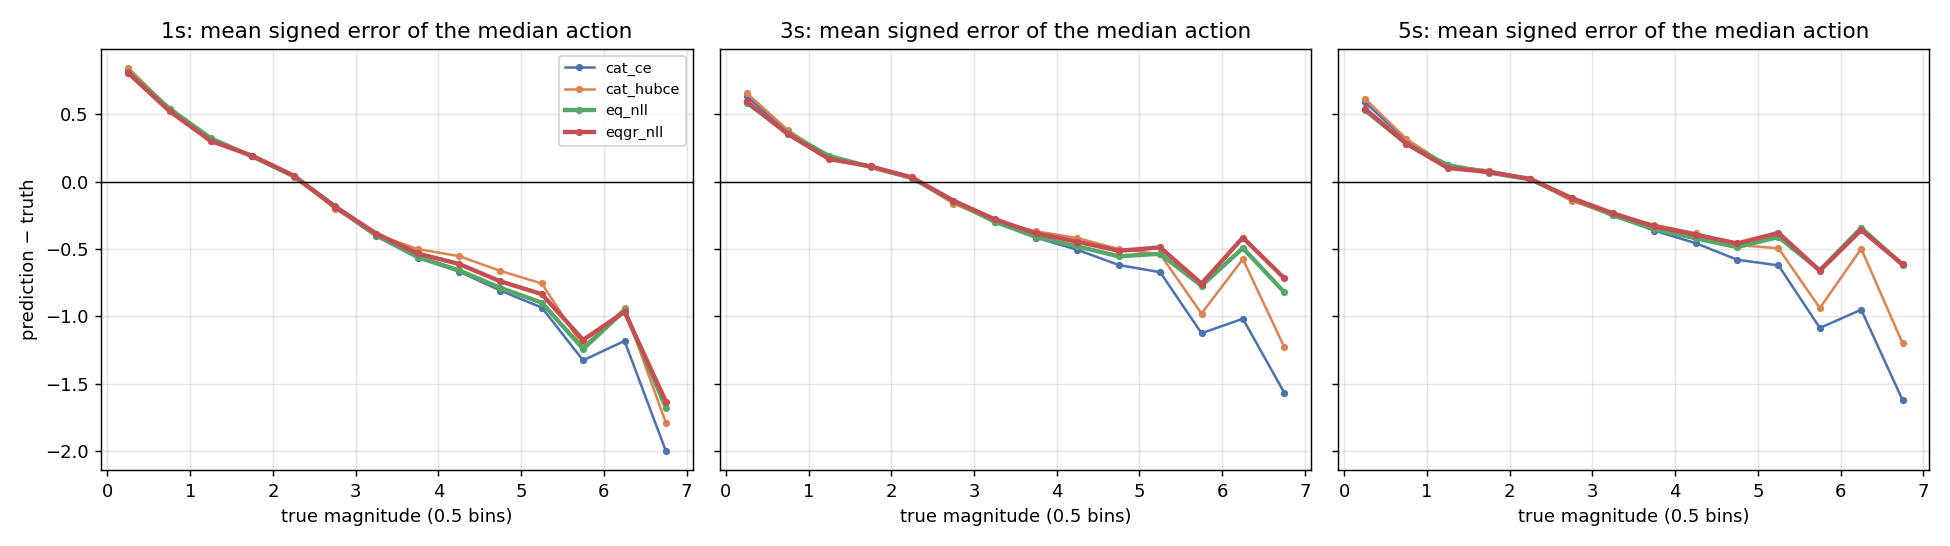

In [4]:
for f in ('frontier_Mge4MAE.png', 'frontier_Mge4eventMAE.png', 'frontier_Mge5MAE.png', 'frontier_CVaR95.png', 'bias_by_magnitude.png'):
    display(Image(filename='figures/' + f))

## 4. Mechanism: does the prediction respond to amplitude?

We multiply the held-out ground motion by 10^δ and record the change in the predicted
median. For an amplitude-defined magnitude the change should be close to δ. A model that
saturates in the sparse upper tail moves much less. The equivariant head moves exactly
κ(s)·δ by construction; the free heads have to learn this response from data.

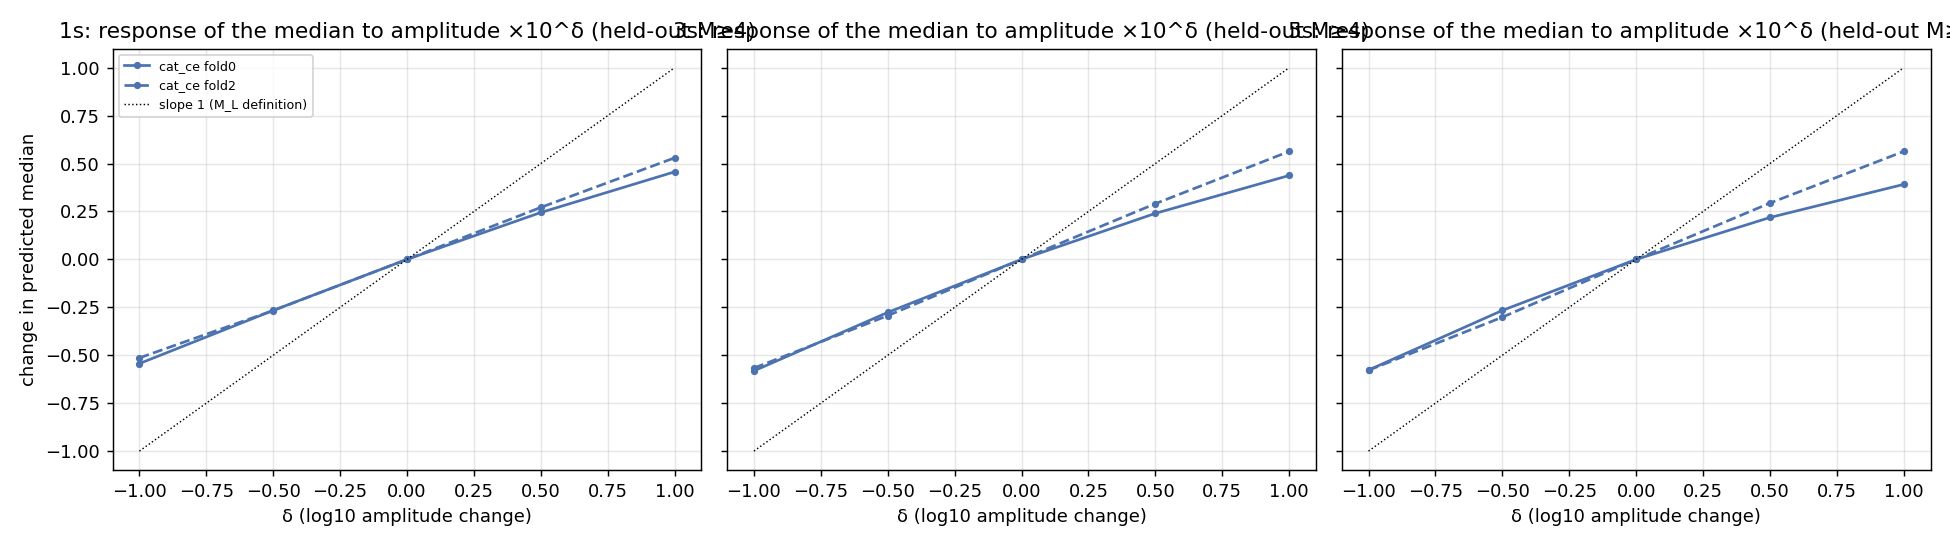

eqgr_nll fold0 {'1s': 0.654, '3s': 0.728, '5s': 0.756}
eqgr_nll fold2 {'1s': 0.63, '3s': 0.682, '5s': 0.7}
mixgr_nll fold0 {'1s': 0.526, '3s': 0.54, '5s': 0.508}
mixgr_nll fold2 {'1s': 0.553, '3s': 0.594, '5s': 0.604}


In [5]:
display(Image(filename='figures/amplitude_response.png'))
diag = json.load(open('results/diagnostics_eqgr_nll_mixgr_nll.json'))
for arm, d in diag.items():
    for f, g in d['amplitude_response'].items():
        print(arm, f, {k: round(v['slope_up'], 3) for k, v in g['M>=4'].items()})

## 5. Classical feature + gradient-boosting baseline (E3WS-style)

In [6]:
gbm = json.load(open('results/gbm_e3ws_summary.json'))
pd.DataFrame({d: {k: round(v[k], 4) for k in ('MAE', 'MedAE', 'CVaR95', 'M>=4_MAE', 'M>=4_eventMAE', 'M>=5_MAE')} for d, v in gbm.items()})

,1s,3s,5s
MAE,0.3587,0.3298,0.3100
MedAE,0.2716,0.2475,0.2290
CVaR95,1.2651,1.1866,1.1496
M>=4_MAE,0.8747,0.7682,0.7133
M>=4_eventMAE,0.8682,0.7681,0.7146
M>=5_MAE,1.2698,1.0640,0.9608


## Findings (from FINDINGS.md)

# Findings log (newest first)

All numbers are pooled out-of-fold predictions over 1,159,249 INSTANCE records (346 M≥4
events, 31 M≥5) from 5 leave-sequence-out folds. Δ = arm − reference, with 95% cluster-bootstrap
intervals (1,000 replicates; whole GK sequences resampled). Negative Δ in an error is better.

## 2026-10-19 07:40 UTC — gains survive two-seed ensembling

eqgr (seeds 1+2, posterior mixture) − cat_ce (seeds 1+2), median action:

| | 1 s | 3 s | 5 s |
|---|---|---|---|
| Δ bulk MAE | −.0005 [−.0026,+.0013] | **−.0028 [−.0050,−.0009]** | **−.0048 [−.0062,−.0039]** |
| Δ M≥4 MAE | **−.031 [−.049,−.011]** | **−.044 [−.069,−.020]** | **−.056 [−.089,−.027]** |
| Δ M≥5 MAE | **−.087 [−.155,−.012]** | **−.205 [−.309,−.100]** | **−.263 [−.385,−.154]** |
| Δ M≥4 event-MAE | **−.022 [−.042,−.003]** | **−.036 [−.065,−.014]** | **−.047 [−.083,−.022]** |
| bulk-capped best M≥4 / M≥5 | **−.068 / −.114** | **−.130 / −.240** | **−.160 / −.287** |

Ensembling lowers both arms' bulk MAE by ≈.005 (single seed → 2-seed), but the tail gap is
unchanged, so the improvement is not seed noise or a variance effect. With ensembles, every
tail metric at every deadline has a 95% interval excluding zero; bulk is equal (1 s) or better.

## 2026-10-19 06:40 UTC — per-fold consistency and the Emilia exception

Arm − mix_nll per held-out fold (median action; bulk / M≥4 / M≥4-event):
* **mixgr** improves M≥4 in 14/15 fold×deadline cells and bulk in 13/15. Both bulk
  exceptions are in fold 1, the smallest fold (9.8k records).
* **eqgr** improves the tail in folds 0, 2, 3, 4 at every deadline (fold 0, the unseen M6.5
  Central Italy sequence: M≥4 −.046 / −.038 / −.056). It is **worse in fold 1** (M≥4 +.06 at
  1–3 s, +.044 at 5 s; bulk +.003 to +.005).
* Fold 1 is the **2012 Emilia (Po Plain) sequence**: M5.8 and M5.6, 32 M≥4 events, 24 of them
  ML-labelled. All models underestimate it. eqgr's extra error is on the **ML-labelled**
  events (3 s bias −.48 vs −.42 for mix_nll), while it is better on the Mw-labelled ones (5 s
  bias −.08 vs −.18). The equivariant head learns one amplitude slope κ(s) ≈ 0.7, close to Mw's
  ⅔ scaling. ML scales ≈1:1 with amplitude, so a sequence dominated by large ML labels is where
  a single learned slope fits worst. **Limitation and future work:** scale-specific slopes
  (an ML and an Mw head) or magnitude-type-homogeneous labels.

## 2026-10-19 06:30 UTC — full attribution against the strongest existing baseline (TEAM-LM-style free mixture)

All 1,159,249 records; Δ = arm − `mix_nll` (free Gaussian-mixture posterior, the strongest
existing-method baseline here). Median action; 95% cluster-bootstrap CIs.

| | 1 s | 3 s | 5 s |
|---|---|---|---|
| cat_ce: Δ bulk / Δ M≥4 / Δ M≥5 | −.0002 / **+.016** / **+.061** | **+.0012 / +.030 / +.095** | **+.0018 / +.033 / +.114** |
| **mixgr**: Δ bulk | **−.0011 [−.0019,−.0006]** | **−.0025 [−.0030,−.0022]** | **−.0032 [−.0035,−.0027]** |
| **mixgr**: Δ M≥4 | **−.013 [−.022,−.003]** | **−.011 [−.018,−.003]** | **−.012 [−.020,−.004]** |
| **mixgr**: Δ M≥4 event | **−.012 [−.021,−.002]** | **−.010 [−.018,−.001]** | **−.011 [−.020,−.002]** |
| **mixgr**: bulk-capped M≥4 / M≥5 | **−.070 / −.080** | **−.107 / −.094** | **−.115 / −.082** |
| **eqgr**: Δ bulk | −.0002 [−.0017,+.0008] | **−.0015 [−.0028,−.0006]** | **−.0032 [−.0038,−.0029]** |
| **eqgr**: Δ M≥4 | **−.020 [−.034,−.002]** | −.015 [−.028,+.001] | **−.023 [−.040,−.005]** |
| **eqgr**: Δ M≥5 | −.032 [−.119,+.040] | −.115 [−.246,+.000] | **−.141 [−.289,−.021]** |
| **eqgr**: bulk-capped M≥4 / M≥5 | −.033 / −.032 (n.s.) | **−.076 / −.143** | **−.114 / −.169** |
| eq_nll (no prior factor): Δ bulk | **+.0051** | **+.0046** | **+.0032** |

**Interpretation**
1. A smooth parametric mixture head (as in TEAM-LM) already beats a categorical head on the
   tail. That part is prior art.
2. **New, the Gutenberg–Richter-factorized posterior** p(m|x) ∝ L_θ(m|x)·e^{φ(m)}, with φ
   learned, free below M3.5 and GR-linear above. On top of the mixture it improves bulk,
   M≥4 and event-level M≥4 at every deadline, all CIs excluding zero: a strict Pareto gain
   over the strongest baseline.
3. **New, the scale-equivariant likelihood** (eqgr) adds extrapolation for the largest events
   (M≥5: −.115 / −.141 at 3 / 5 s vs mix; .548 vs .655 for mixgr at 5 s). Without the
   prior factor, equivariance costs ≈+.005 bulk MAE because of the M2.0 label-prior cliff. The
   two components are complementary and should be used together.

## 2026-10-19 05:40 UTC — replicated across seeds; ablation attributes the gain

**eqgr seed 2 − cat_ce (median action):** bulk −.0000 [−.0022,+.0016] / **−.0021 [−.0044,−.0001]** /
**−.0045 [−.0057,−.0037]**; M≥4 **−.030 [−.052,−.008] / −.042 [−.069,−.017] / −.055 [−.089,−.023]**;
M≥5 **−.085 [−.151,−.014] / −.198 [−.315,−.087] / −.255 [−.397,−.141]**; M≥4 event-MAE
**−.021 [−.044,−.002] / −.035 [−.065,−.013] / −.045 [−.082,−.018]** (1 / 3 / 5 s). Seed 1 and
seed 2 agree to within ≈.006 on every tail metric.

**Probabilistic quality (both seeds):** eqgr beats cat_ce on NLL, CRPS, and Brier(M≥4) and
Brier(M≥5) at every deadline. Mean P(M≥4) on true M≥4 records rises from .374/.445/.467 to
≈.40/.49/.52, while on M<3.5 records it moves only from .0072/.0051/.0042 to .0079/.0055/.0046.

**Ablation `mixgr` (free mixture × the identical learned prior factor):**

| median action | 1 s | 3 s | 5 s |
|---|---|---|---|
| cat_ce − mixgr, M≥4 MAE | +.029 [+.010,+.048] | +.041 [+.017,+.067] | +.044 [+.018,+.073] |
| cat_ce − mixgr, M≥5 MAE | +.085 [+.040,+.120] | +.137 [+.071,+.191] | +.156 [+.083,+.220] |
| eqgr − mixgr, M≥4 MAE | −.007 [−.015,+.008] | −.004 [−.013,+.009] | −.012 [−.021,+.002] |
| eqgr − mixgr, M≥5 MAE | −.007 [−.064,+.058] | −.073 [−.153,+.022] | **−.100 [−.186,−.009]** |
| eqgr − mixgr, bulk MAE | +.0009 [−.0000,+.0015] | +.0010 [−.0001,+.0018] | −.0000 [−.0008,+.0004] |

* The **Gutenberg–Richter-factorized posterior** (smooth likelihood × learned global log-prior:
  free in the bulk, GR-linear above M3.5) gives most of the M≥4 improvement and preserves the
  bulk. It takes over the label-prior structure (the M2.0 cliff, the steep GR decay) that a
  categorical head must otherwise learn per input, and underfits in the rare bins.
* **Scale equivariance** adds extrapolation for the *largest* events: M≥5 MAE at 5 s
  .548 (eqgr) vs .655 (mixgr) vs .818 (cat_ce), at a ≈.001 (0.3%) bulk cost at 1–3 s.
* Still pending: `mix_nll` (free mixture without the prior factor) to separate the mixture
  family from the factorization; augmentation / LDS baselines; seed 3; standard split.

## 2026-10-19 03:45 UTC — eqgr (equivariant likelihood × learned bulk prior × GR tail) improves the tail at all deadlines without worsening the bulk (seed 1)

**Same decision rule (posterior median) for both, eqgr − cat_ce:**

| | 1 s | 3 s | 5 s |
|---|---|---|---|
| Δ bulk MAE | −.0000 [−.0025,+.0019] | **−.0027 [−.0046,−.0013]** | **−.0050 [−.0062,−.0044]** |
| Δ M≥4 MAE | **−.036 [−.060,−.011]** | **−.045 [−.075,−.017]** | **−.056 [−.092,−.024]** |
| Δ M≥5 MAE | **−.093 [−.175,−.003]** | **−.210 [−.334,−.092]** | **−.255 [−.401,−.137]** |
| Δ M≥4 event-MAE | −.025 [−.053,+.002] | **−.036 [−.072,−.008]** | **−.046 [−.086,−.015]** |

MedAE (.2402/.1929/.1649 vs .2398/.1957/.1699), CVaR95 (1.214/1.059/.989 vs 1.215/1.058/.990)
and the false-M4 rate (.0008/.0006/.0005, identical) are unchanged or better.

**Bulk-capped best tail** (each arm picks its best tail-weight r subject to bulk MAE ≤ cat_ce's):
M≥4 MAE −.065 [−.112,−.003] (1 s), **−.128 [−.150,−.101] (3 s), −.161 [−.186,−.127] (5 s)**;
M≥5 MAE −.101 [−.181,−.023], −.245 [−.350,−.143], −.282 [−.407,−.173].

* At 3 s and 5 s the eqgr frontier lies strictly below every baseline across the whole
  bulk range (`figures/frontier_Mge4MAE.png`).
* At 1 s the gain is real at the operating point but modest. With a 0.2% bulk tolerance the
  M≥4 gap is −.025 [−.081,+.035], and the frontiers converge for aggressive r. This is
  physically expected: at 1 s large ruptures are still growing.
* The ablation without the prior factor (eq_nll) loses bulk accuracy (+.005 at 1 s). The
  equivariant constraint and the learned bulk prior are both needed.
* **Caveats still open:** one optimization seed (seed-2/3 runs queued); `mixgr` ablation (free
  mixture × same prior) queued to separate equivariance from the prior factor; augmentation /
  LDS / free-mixture baselines queued. eqgr was specified before the eq_nll results were seen
  (queue2 created 23:30 UTC); later variants are exploratory.

## 2026-10-19 02:20 UTC — interim: equivariance fixes the largest events; bulk cost traced to a label-prior cliff

### Baseline (cat_ce, categorical CE, median action)

| deadline | MAE | MedAE | CVaR95 | M≥4 MAE | M≥4 bias | M≥5 MAE |
|---|---|---|---|---|---|---|
| 1 s | .3272 | .2398 | 1.215 | .7814 | −.733 | 1.110 |
| 3 s | .2714 | .1957 | 1.058 | .6101 | −.557 | .860 |
| 5 s | .2400 | .1699 | .990 | .5660 | −.511 | .818 |

* The tail-weighted median (your "×r tail mass, take median" rule) is almost free near r = 1.
  At 1 s, r = 2 raises bulk MAE by only +.0009 but cuts M≥4 MAE from .781 to .712. So any new
  posterior is judged at **matched bulk MAE**, not at its own default action.
* The classical E3WS-style feature + gradient-boosting baseline is far weaker at every
  deadline (5 s: MAE .310, M≥4 .713, M≥5 .961).

### Negative: the previous project's strongest recipe (emphasized Huber + 0.075 CE) is dominated

At the median action it lowers M≥4 MAE by .06–.09 but raises bulk MAE by +.006. On the
frontier, matching the CE posterior's M≥4 MAE costs **+.0049 [+.0040,+.0059] (1 s),
+.0054 [+.0046,+.0060] (3 s), +.0059 [+.0043,+.0073] (5 s)** more bulk MAE. Its apparent tail
gain is a move along the trade-off curve, not a better posterior.

### Mechanism evidence: the free model saturates

Scaling held-out M≥4 ground motion ×10 raises the categorical model's predicted median by only
**0.39–0.58** magnitude units. In the unseen Central Italy fold at 5 s the response is 0.39.
The amplitude–magnitude relation implies ≈1. Under a Gutenberg–Richter prior the Bayes
posterior is exactly shift-equivariant in log amplitude, even with unknown distance
(THEORY.md). The free network's flattened response is learned under-extrapolation.

### Scale-equivariant head (eq_nll): large gains for the largest events, but a bulk cost

| deadline | Δ bulk MAE | Δ M≥4 MAE | Δ M≥5 MAE | M≥5 at matched bulk |
|---|---|---|---|---|
| 1 s | +.0052 [+.0021,+.0077] | −.001 [−.014,+.018] | −.038 [−.108,+.038] | n/a (frontier never reaches ref bulk) |
| 3 s | +.0034 [−.0001,+.0065] | −.020 [−.037,+.001] | **−.185 [−.278,−.084]** | **−.117 [−.213,−.036]** |
| 5 s | +.0014 [−.0017,+.0039] | **−.036 [−.065,−.007]** | **−.249 [−.374,−.137]** | −.101 [−.219,+.049] |

(median action, eq − cat_ce)

* On the unseen 2016–17 Central Italy sequence (fold 0, includes the M6.5), the M≥5 MAE at 5 s
  falls from **1.008 to 0.550**. The bias for M6.5+ records goes from −1.62 to −0.62.
* **Where the bulk cost comes from:** essentially all of it is the M2.0–2.5 bin (44% of
  records; 1 s MAE .219 → .243). Every other bin is equal or better. The INSTANCE label
  histogram has a 9× cliff at M2.0 (14,790 records at M1.9 vs 130,227 at M2.0), a dataset
  selection rule rather than physics. A categorical head learns the cliff exactly; a smooth
  equivariant likelihood cannot.
* **Verdict for eq_nll alone:** it does not meet the objective (bulk is not preserved at 1 s).
  The next arm, `eqgr` (equivariant likelihood × free 0.1-bin prior below M3.5 × GR-linear tail
  prior), is designed to absorb exactly this cliff while keeping the equivariant tail.

Figures: `figures/frontier_*.png`, `figures/bias_by_magnitude.png`, `figures/amplitude_response.png`.